> **Petunjuk penggunaan notebook:** Jalankan sel kode secara berurutan. Dataset pada contoh ini bersifat sintetis. Grafik akan muncul setelah sel kode yang memanggil `plt.show()` dijalankan.


# TUGAS: IMPLEMENTASI DAN EVALUASI 5 PROMPT OPTIMASI UNTUK GEOSFISIKA
## Framework Rekayasa Prompt: R–T–C–I–K–O–Q–V

**Nama:** Andrew Rizky Patulak

**NIM:** H061251027 

**Mata Kuliah:** Kecerdasan Artifisial untuk Geofisika  


>

## Daftar Topik
1. Optimasi inversi anomali gravitasi dengan regularisasi
2. Estimasi parameter anomali magnetik menggunakan pencarian grid
3. Optimasi lintasan survei geofisika dengan fungsi biaya
4. Penentuan lokasi stasiun pengamatan dengan pendekatan greedy
5. Optimasi parameter model kecepatan menggunakan algoritma evolusioner sederhana

---

# TOPIK 1: OPTIMASI INVERSI ANOMALI GRAVITASI DENGAN REGULARISASI

## A. Latar Belakang Teori dan Konsep Fisis
Inversi gravitasi bertujuan memperkirakan parameter bawah permukaan dari anomali gravitasi yang terukur. Masalah inversi umumnya tidak unik: beberapa model bawah permukaan dapat menghasilkan respons yang hampir sama. Regularisasi digunakan untuk menyeimbangkan kecocokan data dan kompleksitas model.

Fungsi objektif kuadrat terkecil teratur dapat ditulis:

\[
J(\mathbf{m})=\|\mathbf{Gm}-\mathbf{d}\|_2^2+\lambda\|\mathbf{m}\|_2^2
\]

dengan:
- \(\mathbf{d}\): data anomali teramati,
- \(\mathbf{G}\): matriks respons sederhana,
- \(\mathbf{m}\): parameter model,
- \(\lambda\): bobot regularisasi.

Nilai \(\lambda\) terlalu kecil dapat membuat model mengikuti noise; nilai terlalu besar dapat membuat model terlalu halus atau terlalu kecil.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
**R — Role:** Bertindak sebagai analis inversi geofisika.  
**T — Task:** Membandingkan inversi tanpa regularisasi dan dengan regularisasi L2.  
**C — Context:** Gunakan model linear sintetis dan data yang mengandung noise acak.  
**I — Input:** Matriks sensitivitas, data observasi, dan beberapa nilai \(\lambda\).  
**K — Constraints:** Gunakan satuan konsisten; jangan menyebut data sintetis sebagai data lapangan.  
**O — Output:** Tampilkan nilai parameter, residual, dan grafik perbandingan.  
**Q — Quality:** Pastikan dimensi matriks sesuai dan residual dihitung dari prediksi model.  
**V — Verification:** Periksa apakah regularisasi mengurangi nilai parameter ekstrem dan jelaskan trade-off-nya.

## C. Implementasi Python

lambda= 0.0: model=[ 2.088 -1.037  1.401], residual=0.0913
lambda=0.05: model=[ 1.927 -0.809  1.243], residual=0.2072
lambda= 0.5: model=[ 1.272 -0.044  0.696], residual=0.8914
lambda= 2.0: model=[0.721 0.243 0.393], residual=1.4665


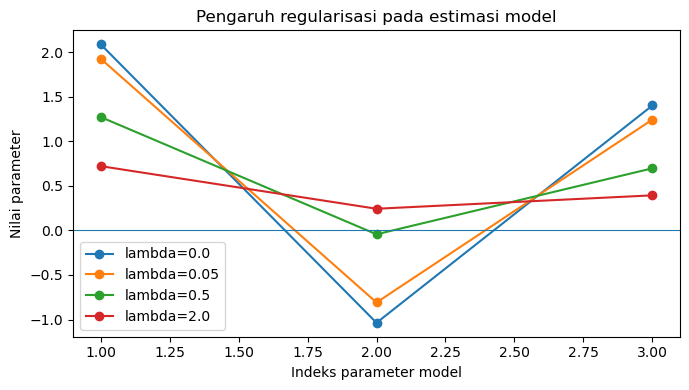

In [23]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(17)
G = np.array([
    [1.0, 0.2, 0.0],
    [0.8, 0.5, 0.1],
    [0.4, 0.9, 0.2],
    [0.1, 0.7, 0.8],
    [0.0, 0.3, 1.0],
    [0.2, 0.6, 0.7]
])
m_true = np.array([2.0, -1.0, 1.5])
d = G @ m_true + rng.normal(0, 0.08, size=G.shape[0])

lambdas = [0.0, 0.05, 0.5, 2.0]
results = []
for lam in lambdas:
    A = G.T @ G + lam * np.eye(G.shape[1])
    m_est = np.linalg.solve(A, G.T @ d)
    residual = np.linalg.norm(G @ m_est - d)
    results.append((lam, m_est, residual))

for lam, model, residual in results:
    print(f"lambda={lam:>4}: model={np.round(model, 3)}, residual={residual:.4f}")

plt.figure(figsize=(7, 4))
for lam, model, _ in results:
    plt.plot(range(1, len(model)+1), model, marker="o", label=f"lambda={lam}")
plt.axhline(0, linewidth=0.8)
plt.xlabel("Indeks parameter model")
plt.ylabel("Nilai parameter")
plt.title("Pengaruh regularisasi pada estimasi model")
plt.legend()
plt.tight_layout()
plt.show()


## D. Pembahasan Hasil dan Verifikasi Mutu Prompt
- Saat \(\lambda=0\), model hanya meminimalkan residual data.
- Saat \(\lambda\) meningkat, estimasi parameter cenderung mengecil karena penalti L2.
- Model terbaik tidak otomatis memiliki residual terkecil; pemilihan regularisasi perlu mempertimbangkan stabilitas dan pengetahuan geologi.
- **Verifikasi:** dimensi \(G\) adalah \(6\times3\), sehingga \(Gm\) menghasilkan enam prediksi. Residual dihitung dengan membandingkan prediksi terhadap data sintetis.

---

# TOPIK 2: ESTIMASI PARAMETER ANOMALI MAGNETIK DENGAN PENCARIAN GRID

## A. Latar Belakang Teori dan Konsep Fisis
Anomali magnetik dapat digunakan untuk memperkirakan posisi dan kekuatan sumber magnetik. Untuk latihan ini, respons sumber disederhanakan menjadi fungsi berbentuk Gaussian. Penyederhanaan ini berguna untuk menguji strategi optimasi, tetapi bukan pengganti model magnetik fisik penuh.

Model sintetis:

\[
\Delta T(x)=A\exp\left[-\frac{(x-x_0)^2}{2\sigma^2}\right]+c
\]

Parameter yang dicari adalah amplitudo \(A\), pusat anomali \(x_0\), lebar \(\sigma\), dan offset \(c\). Pencarian grid menguji kombinasi parameter dan memilih kombinasi dengan jumlah kuadrat residual paling kecil.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
- **R:** Spesialis pemodelan data magnetik.
- **T:** Buat pencarian grid untuk mendapatkan parameter model yang cocok.
- **C:** Data anomali sintetis satu dimensi dengan noise.
- **I:** Posisi pengamatan dan nilai anomali.
- **K:** Batasi parameter pada rentang yang masuk akal dan gunakan seed acak tetap.
- **O:** Tampilkan parameter terbaik dan grafik data versus model.
- **Q:** Laporkan fungsi objektif dan hindari menyamakan model Gaussian dengan model sumber magnetik lengkap.
- **V:** Periksa apakah pusat anomali hasil berada dekat dengan pusat data pembangkit sintetis.

## C. Implementasi Python

Parameter terbaik: {'A': np.float64(7.5), 'x0': np.float64(18.0), 'sigma': np.float64(24.0), 'c': np.float64(0.6), 'misfit': np.float64(0.0757342750254698)}


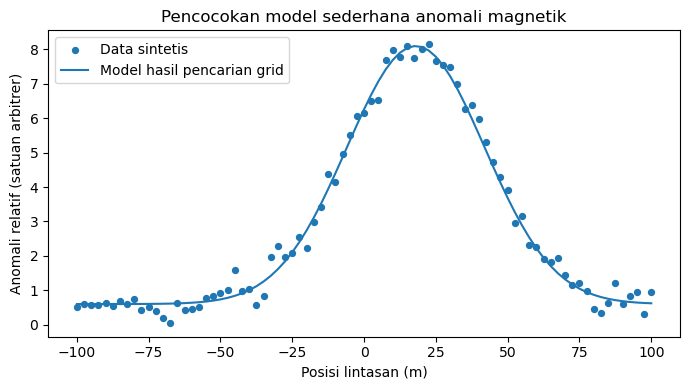

In [24]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(29)
x = np.linspace(-100, 100, 81)
y = 7.5 * np.exp(-((x - 18.0)**2) / (2 * 24.0**2)) + 0.6
y_obs = y + rng.normal(0, 0.25, size=x.size)

best = {"misfit": np.inf}
for A in np.linspace(5.5, 9.5, 17):
    for x0 in np.linspace(0, 35, 36):
        for sigma in np.linspace(15, 35, 21):
            for c in np.linspace(0.0, 1.2, 7):
                pred = A * np.exp(-((x - x0)**2) / (2 * sigma**2)) + c
                misfit = np.mean((y_obs - pred)**2)
                if misfit < best["misfit"]:
                    best = {"A": A, "x0": x0, "sigma": sigma,
                            "c": c, "misfit": misfit}

fit = best["A"] * np.exp(
    -((x - best["x0"])**2) / (2 * best["sigma"]**2)
) + best["c"]

print("Parameter terbaik:", best)
plt.figure(figsize=(7, 4))
plt.scatter(x, y_obs, s=18, label="Data sintetis")
plt.plot(x, fit, label="Model hasil pencarian grid")
plt.xlabel("Posisi lintasan (m)")
plt.ylabel("Anomali relatif (satuan arbitrer)")
plt.title("Pencocokan model sederhana anomali magnetik")
plt.legend()
plt.tight_layout()
plt.show()



## D. Pembahasan Hasil dan Verifikasi Mutu Prompt
- Pencarian grid mudah diperiksa dan hasilnya dapat diulang, tetapi jumlah evaluasi meningkat ketika resolusi grid diperhalus.
- Parameter hasil dibatasi oleh rentang pencarian. Jika nilai optimum berada di tepi rentang, rentang tersebut perlu ditinjau kembali.
- **Verifikasi:** misfit merupakan rata-rata kuadrat selisih data dan prediksi; grafik digunakan untuk memeriksa kecocokan secara visual.
- Karena respons yang digunakan berbentuk Gaussian, hasil hanya menunjukkan keberhasilan optimasi pada model sederhana, bukan interpretasi magnetik unik.

---

# TOPIK 3: OPTIMASI LINTASAN SURVEI GEOFISIKA DENGAN FUNGSI BIAYA

## A. Latar Belakang Teori dan Konsep Fisis
Perencanaan lintasan survei perlu menyeimbangkan jarak tempuh, waktu, dan prioritas area target. Dalam contoh ini, sejumlah titik target diberi bobot kepentingan. Biaya lintasan didefinisikan sebagai jumlah jarak antar-titik; bobot target dapat dipakai sebagai penalti jika target penting dilewati.

\[
J = \sum_{i=1}^{n-1} d(p_i,p_{i+1})+
\alpha\sum_{j\in \text{target terlewat}}w_j
\]

Contoh berikut membandingkan urutan titik sederhana berdasarkan nearest-neighbor dengan lintasan yang mengunjungi semua titik. Ini adalah heuristik praktis, bukan jaminan solusi global optimum.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
- **R:** Perencana survei geofisika.
- **T:** Susun urutan kunjungan titik untuk mengurangi jarak lintasan.
- **C:** Koordinat titik pengukuran sintetis pada bidang dua dimensi.
- **I:** Daftar koordinat titik.
- **K:** Mulai dari titik yang ditetapkan; kunjungi setiap titik satu kali.
- **O:** Tampilkan urutan, total jarak, dan peta lintasan.
- **Q:** Hitung jarak Euclidean dan pastikan seluruh titik dikunjungi.
- **V:** Bandingkan hasil dengan urutan awal dan nyatakan bahwa heuristik belum tentu optimum global.

## C. Implementasi Python

Urutan awal: [0, 1, 2, 3, 4, 5, 6, 7] jarak = 51.5
Urutan heuristik: [0, 2, 4, 3, 1, 5, 7, 6] jarak = 49.28


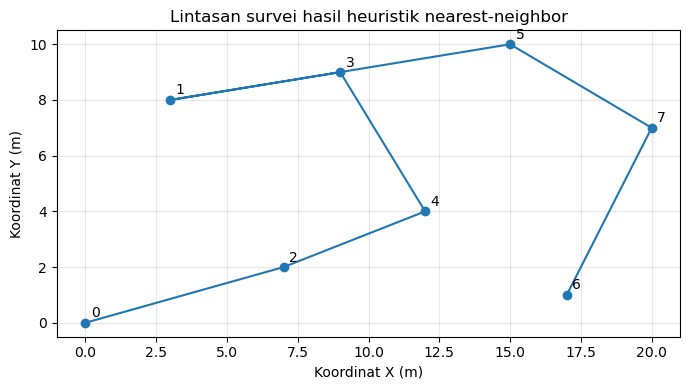

In [25]:
import numpy as np
import matplotlib.pyplot as plt

points = np.array([
    [0, 0], [3, 8], [7, 2], [9, 9],
    [12, 4], [15, 10], [17, 1], [20, 7]
], dtype=float)

def path_length(order):
    p = points[order]
    return np.sum(np.linalg.norm(np.diff(p, axis=0), axis=1))

# Urutan dasar sesuai indeks
baseline = list(range(len(points)))

# Heuristik nearest-neighbor, mulai dari titik 0
remaining = set(range(1, len(points)))
order = [0]
while remaining:
    current = order[-1]
    nxt = min(remaining,
              key=lambda j: np.linalg.norm(points[current] - points[j]))
    order.append(nxt)
    remaining.remove(nxt)

print("Urutan awal:", baseline, "jarak =", round(path_length(baseline), 2))
print("Urutan heuristik:", order, "jarak =", round(path_length(order), 2))

p = points[order]
plt.figure(figsize=(7, 4))
plt.plot(p[:, 0], p[:, 1], "-o")
for i, (px, py) in enumerate(points):
    plt.annotate(str(i), (px, py), xytext=(4, 4), textcoords="offset points")
plt.xlabel("Koordinat X (m)")
plt.ylabel("Koordinat Y (m)")
plt.title("Lintasan survei hasil heuristik nearest-neighbor")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## D. Pembahasan Hasil dan Verifikasi Mutu Prompt
- Nearest-neighbor memilih titik belum dikunjungi yang paling dekat dari posisi saat ini.
- Hasilnya dapat lebih pendek daripada urutan indeks, tetapi tidak dijamin sebagai lintasan terpendek yang mungkin.
- Jarak dihitung dalam satuan yang sama dengan koordinat. Jika koordinat menggunakan meter, total lintasan juga bermakna meter.
- **Verifikasi:** urutan harus memuat seluruh indeks tepat satu kali; jarak dihitung dari pasangan titik berturutan.

---

# TOPIK 4: PENENTUAN LOKASI STASIUN DENGAN PENDEKATAN GREEDY

## A. Latar Belakang Teori dan Konsep Fisis
Penempatan stasiun pengamatan yang terbatas perlu memaksimalkan cakupan area atau target. Pada contoh abstrak ini, setiap kandidat stasiun dapat mengamati beberapa target. Algoritma greedy memilih kandidat yang menambah jumlah target tercakup paling banyak sampai anggaran stasiun terpenuhi.

Jika \(S_i\) adalah himpunan target yang terjangkau kandidat \(i\), maka pada setiap langkah dipilih kandidat yang memberikan pertambahan cakupan terbesar terhadap target yang belum tercakup.

Metode ini sesuai untuk demonstrasi optimasi kombinatorial, tetapi cakupan nyata harus mempertimbangkan topografi, akses, noise, keselamatan, dan karakteristik instrumen.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
- **R:** Perancang jaringan pengamatan geofisika.
- **T:** Pilih lokasi stasiun dari kandidat untuk memaksimalkan cakupan target.
- **C:** Matriks cakupan sintetis berisi target yang dapat diamati setiap kandidat.
- **I:** Matriks biner kandidat-target dan jumlah stasiun yang tersedia.
- **K:** Tidak boleh memilih kandidat yang sama dua kali.
- **O:** Daftar stasiun terpilih, target tercakup, dan persentase cakupan.
- **Q:** Hitung cakupan dari gabungan target, bukan menjumlahkan target yang sama berulang kali.
- **V:** Bandingkan jumlah target tercakup dengan semua target yang tersedia.

## C. Implementasi Python

In [26]:
import numpy as np

# Baris = kandidat stasiun, kolom = target
coverage = np.array([
    [1, 1, 0, 0, 1, 0, 0, 0],
    [0, 1, 1, 1, 0, 0, 0, 0],
    [0, 0, 1, 1, 1, 1, 0, 0],
    [0, 0, 0, 1, 0, 1, 1, 1],
    [1, 0, 0, 0, 0, 1, 1, 1],
    [1, 1, 0, 1, 0, 0, 1, 0]
], dtype=int)

budget = 3
selected = []
covered = set()
available = set(range(coverage.shape[0]))

for _ in range(budget):
    best_candidate = max(
        available,
        key=lambda i: sum(
            coverage[i, j] == 1 and j not in covered
            for j in range(coverage.shape[1])
        )
    )
    selected.append(best_candidate)
    covered.update(np.where(coverage[best_candidate] == 1)[0].tolist())
    available.remove(best_candidate)

total_targets = coverage.shape[1]
print("Kandidat terpilih (indeks mulai 0):", selected)
print("Target tercakup:", sorted(covered))
print(f"Cakupan: {len(covered)}/{total_targets} "
      f"= {100*len(covered)/total_targets:.1f}%")

Kandidat terpilih (indeks mulai 0): [2, 4, 0]
Target tercakup: [0, 1, 2, 3, 4, 5, 6, 7]
Cakupan: 8/8 = 100.0%



## D. Pembahasan Hasil dan Verifikasi Mutu Prompt
- Greedy mengutamakan tambahan cakupan terbesar pada setiap langkah.
- Solusi dapat bergantung pada pola cakupan dan tidak selalu menghasilkan kombinasi terbaik secara global.
- Dalam survei nyata, cakupan biner perlu diganti atau dilengkapi dengan ukuran kualitas data, jarak antarstasiun, biaya akses, dan kondisi lapangan.
- **Verifikasi:** setiap target dihitung satu kali pada himpunan `covered`, sehingga cakupan tidak terduplikasi.

---

# TOPIK 5: OPTIMASI PARAMETER MODEL KECEPATAN DENGAN ALGORITMA EVOLUSIONER SEDERHANA

## A. Latar Belakang Teori dan Konsep Fisis
Dalam pemodelan waktu tempuh, kecepatan bawah permukaan dapat diperkirakan dengan mencocokkan waktu observasi terhadap prediksi model. Untuk medium homogen sederhana, waktu tempuh sumber-penerima adalah:

\[
t_i = \frac{r_i}{v}
\]

dengan \(r_i\) jarak sumber-penerima dan \(v\) kecepatan efektif. Fungsi objektif dapat berupa:

\[
J(v)=\frac{1}{N}\sum_{i=1}^{N}(t_i^{obs}-r_i/v)^2
\]

Algoritma evolusioner sederhana mempertahankan beberapa kandidat kecepatan, memilih kandidat dengan misfit rendah, lalu menghasilkan kandidat baru melalui mutasi. Metode ini menunjukkan konsep pencarian stokastik; untuk model satu parameter, pencarian grid atau optimasi analitik dapat lebih efisien.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
- **R:** Analis pemodelan waktu tempuh.
- **T:** Cari kecepatan efektif yang meminimalkan misfit waktu tempuh.
- **C:** Data waktu tempuh sintetis dari model homogen dengan noise.
- **I:** Jarak sumber-penerima dan waktu terukur.
- **K:** Kecepatan harus positif dan berada pada rentang yang ditentukan.
- **O:** Kecepatan terbaik, misfit, dan grafik waktu observasi versus prediksi.
- **Q:** Gunakan satuan jarak dan waktu yang konsisten.
- **V:** Bandingkan hasil dengan kecepatan pembangkit data sintetis dan periksa residual.

## C. Implementasi Python

Kecepatan terbaik: 1805.9 m/s
Mean squared error: 0.00014461 s^2


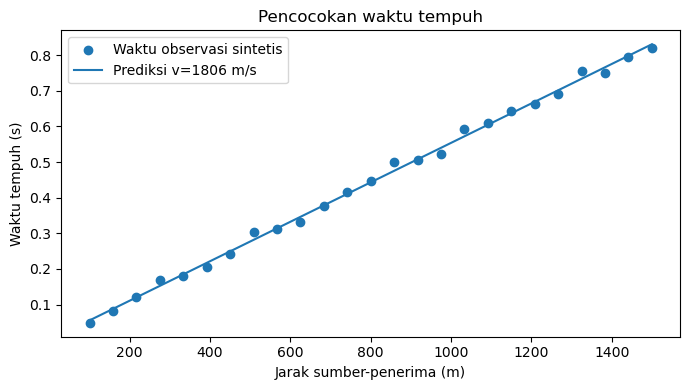

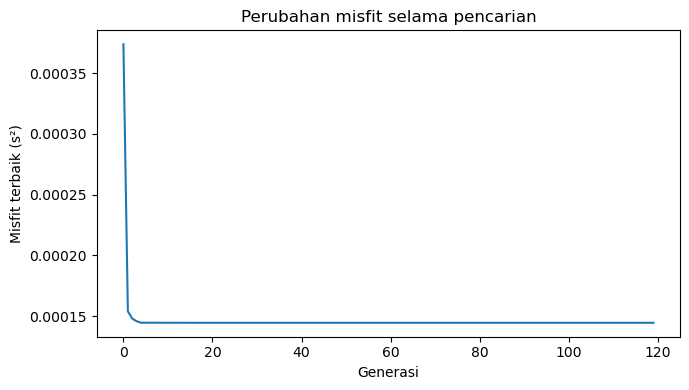

In [27]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(51)
distance_m = np.linspace(100, 1500, 25)
v_synthetic = 1800.0
time_obs = distance_m / v_synthetic + rng.normal(0, 0.012, 25)

def misfit(v):
    if v <= 0:
        return np.inf
    return np.mean((time_obs - distance_m / v)**2)

# Populasi kandidat awal
population = rng.uniform(1000, 3000, 40)
best_history = []

for generation in range(120):
    scores = np.array([misfit(v) for v in population])
    order = np.argsort(scores)
    elites = population[order[:8]]
    best_history.append(scores[order[0]])

    # Kandidat baru: salin elite dan mutasi nilai kecepatan
    children = []
    for _ in range(32):
        parent = rng.choice(elites)
        child = parent + rng.normal(0, 120)
        children.append(np.clip(child, 500, 4000))
    population = np.concatenate([elites, np.array(children)])

best_v = population[np.argmin([misfit(v) for v in population])]
pred = distance_m / best_v
print(f"Kecepatan terbaik: {best_v:.1f} m/s")
print(f"Mean squared error: {misfit(best_v):.8f} s^2")

plt.figure(figsize=(7, 4))
plt.scatter(distance_m, time_obs, label="Waktu observasi sintetis")
plt.plot(distance_m, pred, label=f"Prediksi v={best_v:.0f} m/s")
plt.xlabel("Jarak sumber-penerima (m)")
plt.ylabel("Waktu tempuh (s)")
plt.title("Pencocokan waktu tempuh")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(best_history)
plt.xlabel("Generasi")
plt.ylabel("Misfit terbaik (s²)")
plt.title("Perubahan misfit selama pencarian")
plt.tight_layout()
plt.show()



## D. Pembahasan Hasil dan Verifikasi Mutu Prompt
- Populasi kandidat bergerak menuju kecepatan yang menghasilkan waktu prediksi dekat dengan data observasi.
- Karena metode ini stokastik, hasil dapat berubah jika seed acak atau parameter algoritma diubah.
- Pada model homogen satu parameter, nilai analitik dapat dihitung dari hubungan antara jarak dan waktu. Algoritma evolusioner di sini digunakan sebagai latihan optimasi, bukan sebagai metode paling efisien.
- **Verifikasi:** kecepatan dibatasi positif, satuan waktu menggunakan sekon, dan misfit dihitung dalam sekon kuadrat.

---

